<a href="https://colab.research.google.com/github/irfan060606/Scikit-Learn-Cookbook/blob/main/Chapter_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 6 — Advanced Logistic Regression and Extensions

**Book:** *scikit-learn Cookbook, Third Edition* — John Sukup  
**Chapter topic:** Advanced Logistic Regression and Extensions

Notebook ini mempraktikkan konsep pada Chapter 6 menggunakan scikit-learn. Penjelasan ditulis ulang dengan bahasa yang lebih sederhana dan kode disusun sebagai implementasi latihan mandiri.

## Learning objectives

Setelah menyelesaikan notebook ini, kita diharapkan dapat:

1. Menjelaskan bagaimana logistic regression menghasilkan probabilitas.
2. Menerapkan logistic regression untuk klasifikasi biner dan multiclass.
3. Membandingkan regularisasi L1 (Lasso) dan L2 (Ridge).
4. Membuat model multilabel classification.
5. Mengevaluasi model menggunakan accuracy, confusion matrix, precision, recall, F1-score, ROC, dan AUC.
6. Memvisualisasikan decision boundary pada data dua fitur.

## 1. Logistic regression overview

### Theory

Logistic regression adalah algoritma **klasifikasi**, bukan regresi untuk memprediksi angka kontinu. Model menghitung kombinasi linear dari fitur, lalu mengubahnya menjadi probabilitas menggunakan fungsi sigmoid:

\[
p = \frac{1}{1 + e^{-z}}, \qquad z = \beta_0 + \beta_1x_1 + \cdots + \beta_nx_n
\]

Nilai probabilitas selalu berada di antara 0 dan 1. Dengan threshold yang umum digunakan, yaitu 0.5, model memprediksi kelas 1 ketika probabilitas minimal 0.5 dan kelas 0 ketika nilainya di bawah 0.5. Threshold dapat diubah sesuai kebutuhan masalah.

Koefisien \(\beta\) menunjukkan arah hubungan fitur dengan **log-odds** kelas positif, dengan asumsi fitur lainnya tetap.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer, load_iris, make_multilabel_classification, make_classification
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    precision_score, recall_score, f1_score,
    roc_curve, roc_auc_score, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Imports completed.")

Imports completed.


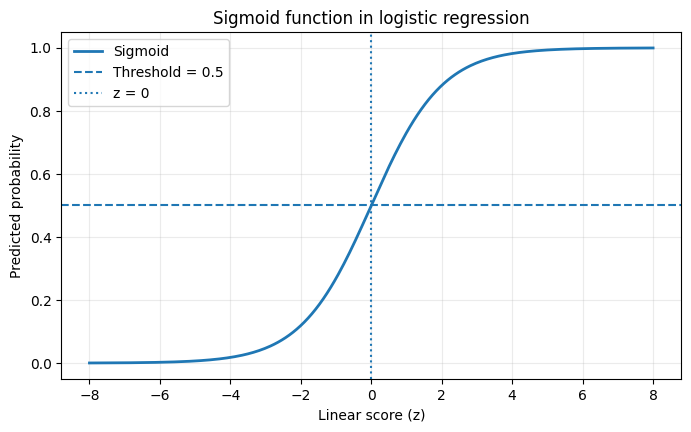

In [2]:
# Plot the sigmoid function
z = np.linspace(-8, 8, 300)
probability = 1 / (1 + np.exp(-z))

plt.figure(figsize=(8, 4.5))
plt.plot(z, probability, linewidth=2, label="Sigmoid")
plt.axhline(0.5, linestyle="--", label="Threshold = 0.5")
plt.axvline(0, linestyle=":", label="z = 0")
plt.xlabel("Linear score (z)")
plt.ylabel("Predicted probability")
plt.title("Sigmoid function in logistic regression")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

**How to read the plot:** ketika skor linear \(z=0\), probabilitasnya 0.5. Skor yang makin positif menghasilkan probabilitas yang mendekati 1, sedangkan skor yang makin negatif menghasilkan probabilitas yang mendekati 0.

### Binary classification with the Breast Cancer dataset

Dataset Breast Cancer Wisconsin sudah tersedia di scikit-learn. Dataset ini memiliki 569 baris dan 30 fitur numerik. Target `0` berarti **malignant**, sedangkan target `1` berarti **benign**. Karena skala fitur berbeda-beda, kita menggunakan `StandardScaler` di dalam `Pipeline`. Scaler hanya belajar dari data training agar tidak terjadi data leakage.

In [3]:
cancer = load_breast_cancer()
X_cancer = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y_cancer = pd.Series(cancer.target, name="target")

print("Feature matrix shape:", X_cancer.shape)
print("Target names:", dict(enumerate(cancer.target_names)))
print("Class counts:")
print(y_cancer.map(dict(enumerate(cancer.target_names))).value_counts())
X_cancer.head()

Feature matrix shape: (569, 30)
Target names: {0: np.str_('malignant'), 1: np.str_('benign')}
Class counts:
target
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X_cancer, y_cancer,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_cancer
)

binary_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
])
binary_model.fit(X_train, y_train)
y_pred = binary_model.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=cancer.target_names))

Test accuracy: 0.986

Classification report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        53
      benign       0.99      0.99      0.99        90

    accuracy                           0.99       143
   macro avg       0.99      0.99      0.99       143
weighted avg       0.99      0.99      0.99       143



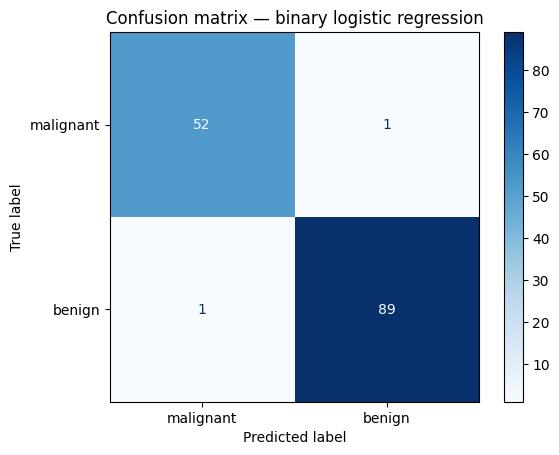

In [5]:
# The confusion matrix shows which classes were mixed up
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=cancer.target_names,
    cmap="Blues",
    values_format="d"
)
plt.title("Confusion matrix — binary logistic regression")
plt.show()

**Interpretation:** accuracy adalah proporsi seluruh prediksi yang benar, tetapi belum menjelaskan jenis kesalahannya. Confusion matrix membantu melihat jumlah prediksi benar dan salah untuk setiap kelas. Dalam konteks medis, perhatikan pula recall untuk kelas yang menjadi fokus risiko; jangan menilai model hanya dari accuracy.

## 2. Multiclass classification techniques

### Theory

Pada **multiclass classification**, satu observasi masuk ke salah satu dari lebih dari dua kelas.

- **One-vs-Rest (OvR):** membuat satu classifier biner untuk setiap kelas. Model kelas tertentu memisahkan kelas tersebut dari gabungan kelas lainnya.
- **Multinomial logistic regression:** melatih model untuk memprediksi probabilitas seluruh kelas secara bersama-sama.

Kinerja strategi dapat berbeda menurut dataset dan pembagian data, sehingga perbandingan perlu menggunakan train/test split yang sama.

In [6]:
iris = load_iris()
X_iris = pd.DataFrame(iris.data, columns=iris.feature_names)
y_iris = pd.Series(iris.target, name="target")

X_train_i, X_test_i, y_train_i, y_test_i = train_test_split(
    X_iris, y_iris,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y_iris
)

# OvR: wrap a binary logistic regression model
ovr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", OneVsRestClassifier(
        LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)
    ))
])
ovr_model.fit(X_train_i, y_train_i)

# With three or more classes, LogisticRegression uses a multinomial fit with lbfgs
multinomial_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(solver="lbfgs", max_iter=3000, random_state=RANDOM_STATE))
])
multinomial_model.fit(X_train_i, y_train_i)

pred_ovr = ovr_model.predict(X_test_i)
pred_multi = multinomial_model.predict(X_test_i)

comparison = pd.DataFrame({
    "Strategy": ["One-vs-Rest", "Multinomial"],
    "Accuracy": [accuracy_score(y_test_i, pred_ovr), accuracy_score(y_test_i, pred_multi)]
})
comparison

,Strategy,Accuracy
0,One-vs-Rest,0.844444
1,Multinomial,0.911111


Classification report — multinomial logistic regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45



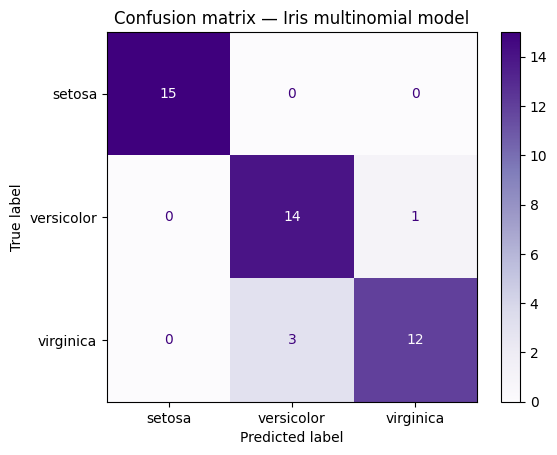

In [7]:
print("Classification report — multinomial logistic regression")
print(classification_report(
    y_test_i, pred_multi,
    labels=[0, 1, 2],
    target_names=iris.target_names,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test_i, pred_multi,
    display_labels=iris.target_names,
    cmap="Purples",
    values_format="d"
)
plt.title("Confusion matrix — Iris multinomial model")
plt.show()

**Interpretation:** jangan menganggap salah satu strategi selalu paling unggul. Perhatikan accuracy bersama precision, recall, F1-score, dan kesalahan antar kelas. Pada Iris, beberapa spesies lebih mudah dipisahkan daripada yang lain.

## 3. Regularization in logistic regression

### Theory

Regularisasi menambahkan penalti pada koefisien supaya model tidak terlalu menyesuaikan diri terhadap data training.

- **L2 (Ridge):** mengecilkan besar koefisien; umumnya koefisien tidak menjadi tepat nol.
- **L1 (Lasso):** dapat membuat sejumlah koefisien tepat nol sehingga membantu seleksi fitur.
- **Parameter `C`:** kebalikan dari kekuatan regularisasi. `C` kecil berarti penalti lebih kuat; `C` besar berarti penalti lebih lemah.

Scaling penting karena penalti koefisien dapat terpengaruh oleh perbedaan skala fitur.

In [8]:
# Use the same split for a fair comparison and scale within each pipeline
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_cancer, y_cancer,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_cancer
)

regularized_models = {
    "L2 (Ridge)": Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(penalty="l2", C=0.5, max_iter=4000, random_state=RANDOM_STATE))
    ]),
    "L1 (Lasso)": Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(penalty="l1", solver="liblinear", C=0.5, max_iter=4000, random_state=RANDOM_STATE))
    ])
}

rows = []
for name, estimator in regularized_models.items():
    estimator.fit(X_train_r, y_train_r)
    predictions = estimator.predict(X_test_r)
    coefficients = estimator.named_steps["logistic"].coef_.ravel()
    rows.append({
        "Model": name,
        "Test accuracy": accuracy_score(y_test_r, predictions),
        "Non-zero coefficients": int(np.count_nonzero(np.abs(coefficients) > 1e-8)),
        "Total features": len(coefficients)
    })

pd.DataFrame(rows)

,Model,Test accuracy,Non-zero coefficients,Total features
0,L2 (Ridge),0.986014,30,30
1,L1 (Lasso),0.986014,12,30


Perbandingan di atas menggunakan pembagian data dan nilai `C` yang sama. Jumlah koefisien non-zero dapat memperlihatkan bagaimana L1 menyeleksi fitur. Hasil angka merupakan hasil eksperimen pada split ini, bukan jaminan bahwa model yang sama akan unggul pada semua dataset.

In [9]:
# Tune the inverse regularization strength C using cross-validation
l2_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(penalty="l2", max_iter=4000, random_state=RANDOM_STATE))
])

search = GridSearchCV(
    estimator=l2_pipeline,
    param_grid={"logistic__C": [0.01, 0.1, 1, 10, 100]},
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)
search.fit(X_train_r, y_train_r)

print("Best parameter:", search.best_params_)
print(f"Best mean CV accuracy: {search.best_score_:.3f}")
print(f"Held-out test accuracy: {accuracy_score(y_test_r, search.predict(X_test_r)):.3f}")

Best parameter: {'logistic__C': 0.1}
Best mean CV accuracy: 0.977
Held-out test accuracy: 0.979


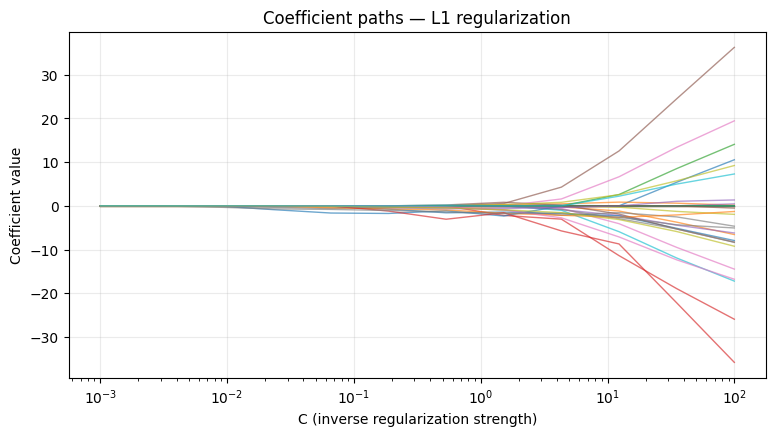

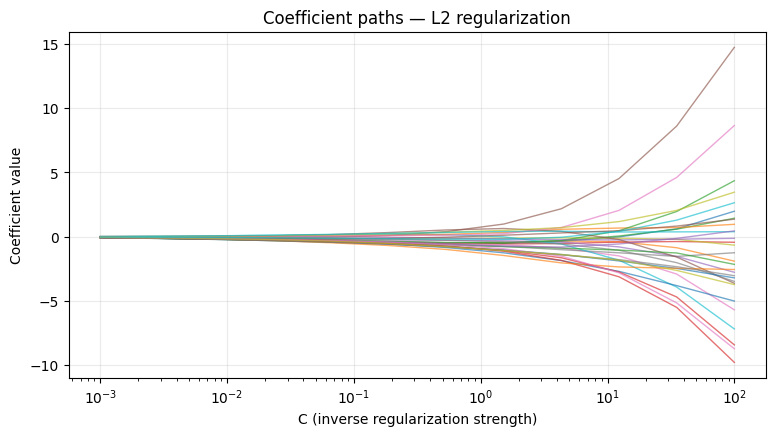

In [10]:
# Compare coefficient paths as C changes
C_values = np.logspace(-3, 2, 12)
coefficient_paths = {"L1": [], "L2": []}

for penalty in ["l1", "l2"]:
    for C in C_values:
        if penalty == "l1":
            estimator = LogisticRegression(penalty="l1", solver="liblinear", C=C, max_iter=4000, random_state=RANDOM_STATE)
            key = "L1"
        else:
            estimator = LogisticRegression(penalty="l2", C=C, max_iter=4000, random_state=RANDOM_STATE)
            key = "L2"
        estimator.fit(StandardScaler().fit_transform(X_train_r), y_train_r)
        coefficient_paths[key].append(estimator.coef_[0])

for key, path_values in coefficient_paths.items():
    paths_array = np.asarray(path_values)
    plt.figure(figsize=(9, 4.5))
    for feature_idx in range(paths_array.shape[1]):
        plt.plot(C_values, paths_array[:, feature_idx], alpha=0.65, linewidth=1)
    plt.xscale("log")
    plt.xlabel("C (inverse regularization strength)")
    plt.ylabel("Coefficient value")
    plt.title(f"Coefficient paths — {key} regularization")
    plt.grid(alpha=0.25)
    plt.show()

**How to read coefficient paths:** saat `C` kecil, penalti lebih kuat dan koefisien cenderung dekat nol. Ketika `C` membesar, penalti melemah. Pada L1, beberapa jalur dapat tetap tepat nol pada sejumlah nilai `C`; L2 biasanya mengecilkan koefisien tanpa memaksanya tepat nol.

## 4. Multilabel classification concepts

### Theory

Pada multiclass biasa, setiap baris mempunyai **satu** label dari beberapa pilihan. Pada **multilabel classification**, sebuah baris bisa memiliki beberapa label sekaligus. Contohnya, sebuah artikel dapat ditandai sebagai “teknologi” dan “bisnis” secara bersamaan.

Salah satu pendekatan sederhana adalah melatih satu classifier biner untuk setiap label. Dalam scikit-learn, `MultiOutputClassifier` dapat mengaplikasikan estimator yang sama ke masing-masing kolom target.

In [11]:
X_ml, y_ml = make_multilabel_classification(
    n_samples=1000,
    n_features=20,
    n_classes=5,
    n_labels=2,
    random_state=RANDOM_STATE
)

X_train_ml, X_test_ml, y_train_ml, y_test_ml = train_test_split(
    X_ml, y_ml,
    test_size=0.30,
    random_state=RANDOM_STATE
)

multilabel_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", MultiOutputClassifier(
        LogisticRegression(solver="liblinear", max_iter=3000, random_state=RANDOM_STATE)
    ))
])
multilabel_model.fit(X_train_ml, y_train_ml)
y_pred_ml = multilabel_model.predict(X_test_ml)

print("Feature matrix shape:", X_ml.shape)
print("Target matrix shape:", y_ml.shape)
print(f"Exact-match accuracy: {accuracy_score(y_test_ml, y_pred_ml):.3f}")
print("\nPer-label report:")
print(classification_report(y_test_ml, y_pred_ml, zero_division=0))

Feature matrix shape: (1000, 20)
Target matrix shape: (1000, 5)
Exact-match accuracy: 0.413

Per-label report:
              precision    recall  f1-score   support

           0       0.78      0.58      0.66       106
           1       0.80      0.78      0.79       160
           2       0.88      0.73      0.80       151
           3       0.71      0.67      0.69       111
           4       0.70      0.45      0.55        51

   micro avg       0.79      0.68      0.73       579
   macro avg       0.77      0.64      0.70       579
weighted avg       0.79      0.68      0.73       579
 samples avg       0.77      0.69      0.69       579



Exact-match accuracy pada multilabel sangat ketat: satu sampel dianggap benar hanya jika **semua** label yang diprediksi tepat. Karena itu, nilainya dapat lebih rendah dibanding skor per label. Periksa juga precision, recall, dan F1 untuk setiap label.

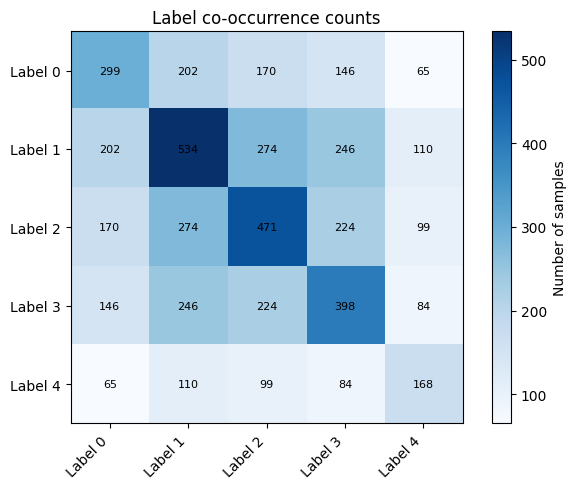

In [12]:
# Visualize how often each pair of labels appears together
cooccurrence = y_ml.T @ y_ml
label_names = [f"Label {i}" for i in range(y_ml.shape[1])]

fig, ax = plt.subplots(figsize=(6.5, 5))
image = ax.imshow(cooccurrence, cmap="Blues")
ax.set_xticks(range(len(label_names)), label_names, rotation=45, ha="right")
ax.set_yticks(range(len(label_names)), label_names)
ax.set_title("Label co-occurrence counts")
for i in range(cooccurrence.shape[0]):
    for j in range(cooccurrence.shape[1]):
        ax.text(j, i, int(cooccurrence[i, j]), ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax, label="Number of samples")
plt.tight_layout()
plt.show()

Pada matriks ini, diagonal berisi jumlah kemunculan tiap label. Nilai di luar diagonal menunjukkan seberapa sering sepasang label muncul bersama. Matriks ini membantu memahami hubungan label, tetapi tidak dengan sendirinya menunjukkan kualitas prediksi model.

## 5. Model evaluation metrics

Metric yang digunakan sebaiknya mengikuti tujuan masalah:

- **Accuracy:** proporsi semua prediksi yang benar.
- **Precision:** dari seluruh prediksi positif, berapa yang benar-benar positif.
- **Recall:** dari semua data yang benar-benar positif, berapa yang berhasil ditemukan model.
- **F1-score:** rata-rata harmonik precision dan recall.
- **Confusion matrix:** rincian prediksi benar dan kesalahan per kelas.
- **ROC curve dan AUC:** mengevaluasi kemampuan pemisahan kelas pada berbagai threshold; AUC yang lebih tinggi biasanya menunjukkan pemeringkatan kelas yang lebih baik.

Di dataset Breast Cancer scikit-learn, target `0` adalah malignant dan target `1` adalah benign. Untuk contoh ROC di bawah, kita mendefinisikan **malignant sebagai kelas positif**, sehingga probabilitas kelas 0 yang dipakai.

In [13]:
# Evaluate malignant cases as the positive class (label 0 in this dataset)
evaluation_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
])
evaluation_model.fit(X_train, y_train)

y_eval_pred = evaluation_model.predict(X_test)
probability_by_class = evaluation_model.predict_proba(X_test)
malignant_probability = probability_by_class[:, list(evaluation_model.classes_).index(0)]

print(f"Accuracy:  {accuracy_score(y_test, y_eval_pred):.3f}")
print(f"Precision for malignant (label 0): {precision_score(y_test, y_eval_pred, pos_label=0):.3f}")
print(f"Recall for malignant (label 0):    {recall_score(y_test, y_eval_pred, pos_label=0):.3f}")
print(f"F1-score for malignant (label 0):   {f1_score(y_test, y_eval_pred, pos_label=0):.3f}")
print(f"ROC AUC (malignant as positive):   {roc_auc_score((y_test == 0).astype(int), malignant_probability):.3f}")
print("\nClass-wise report:")
print(classification_report(y_test, y_eval_pred, target_names=cancer.target_names))

Accuracy:  0.986
Precision for malignant (label 0): 0.981
Recall for malignant (label 0):    0.981
F1-score for malignant (label 0):   0.981
ROC AUC (malignant as positive):   0.998

Class-wise report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        53
      benign       0.99      0.99      0.99        90

    accuracy                           0.99       143
   macro avg       0.99      0.99      0.99       143
weighted avg       0.99      0.99      0.99       143



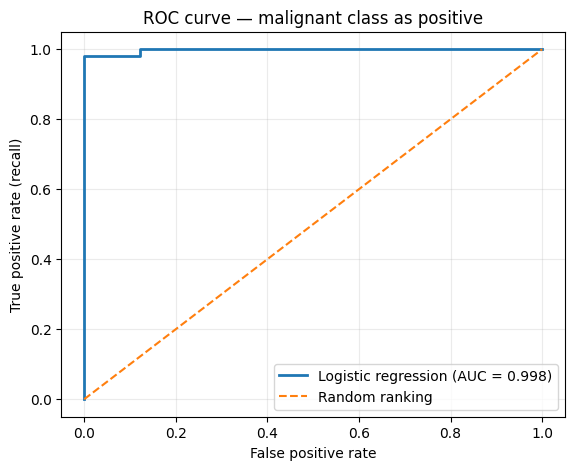

In [14]:
# ROC curve using malignant as the positive class
fpr, tpr, thresholds = roc_curve((y_test == 0).astype(int), malignant_probability)
auc_value = roc_auc_score((y_test == 0).astype(int), malignant_probability)

plt.figure(figsize=(6.5, 5))
plt.plot(fpr, tpr, label=f"Logistic regression (AUC = {auc_value:.3f})", linewidth=2)
plt.plot([0, 1], [0, 1], linestyle="--", label="Random ranking")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("ROC curve — malignant class as positive")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.show()

AUC merangkum kemampuan model mengurutkan sampel positif lebih tinggi daripada sampel negatif pada berbagai threshold. AUC bukan hal yang sama dengan accuracy: accuracy dihitung pada threshold prediksi tertentu, sedangkan ROC/AUC mempertimbangkan banyak threshold. Pada aplikasi nyata, pilih threshold dan metric berdasarkan biaya false positive dan false negative.

## 6. Practical exercises

Latihan berikut merangkum penerapan bab. Kerjakan dengan membaca kode, menjalankannya, lalu tuliskan interpretasi berdasarkan hasil yang tampil.

### Exercise 1 — Build a regularized logistic regression model

Buat model L1 dan L2 pada Breast Cancer dataset, lalu bandingkan test accuracy serta jumlah koefisien yang tidak nol. Pertanyaan: model mana yang menggunakan lebih sedikit fitur pada eksperimen ini? Mengapa hasil ini belum cukup untuk menyimpulkan model itu selalu terbaik?

In [15]:
exercise_regularization = pd.DataFrame(rows)
exercise_regularization

,Model,Test accuracy,Non-zero coefficients,Total features
0,L2 (Ridge),0.986014,30,30
1,L1 (Lasso),0.986014,12,30


### Exercise 2 — Evaluate multiclass logistic regression

Gunakan Iris untuk mengevaluasi model multinomial. Perhatikan class-wise recall dan confusion matrix. Kelas mana yang paling sering tertukar pada pembagian data yang kamu gunakan?

Multinomial Iris accuracy: 0.911


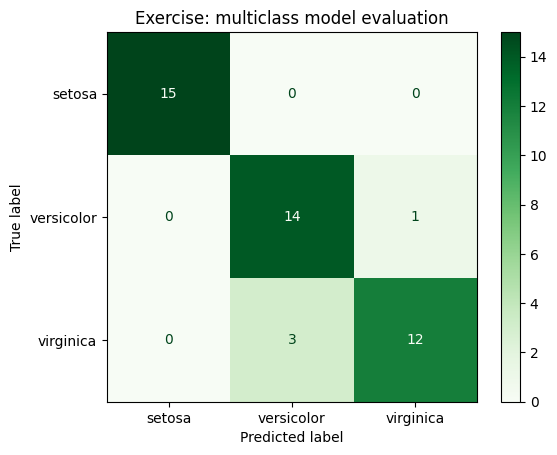

In [16]:
print("Multinomial Iris accuracy:", round(accuracy_score(y_test_i, pred_multi), 3))
ConfusionMatrixDisplay.from_predictions(
    y_test_i, pred_multi,
    display_labels=iris.target_names,
    cmap="Greens",
    values_format="d"
)
plt.title("Exercise: multiclass model evaluation")
plt.show()

### Exercise 3 — Visualize a logistic regression decision boundary

Model berikut menggunakan dua fitur sintetis agar batas keputusan dapat digambar pada bidang dua dimensi. Setiap titik berwarna sesuai kelasnya; latar belakang menunjukkan kelas yang diprediksi model.

Synthetic-data test accuracy: 0.860


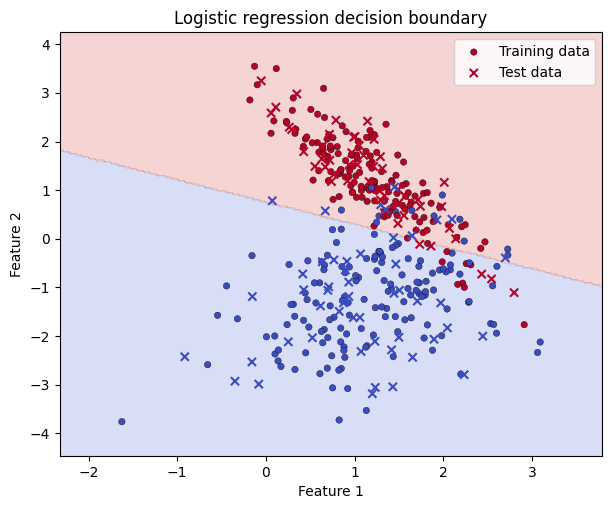

In [17]:
X_syn, y_syn = make_classification(
    n_samples=400,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    class_sep=1.2,
    random_state=RANDOM_STATE
)

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_syn, y_syn,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_syn
)

synthetic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
synthetic_model.fit(X_train_s, y_train_s)
print(f"Synthetic-data test accuracy: {accuracy_score(y_test_s, synthetic_model.predict(X_test_s)):.3f}")

x_min, x_max = X_syn[:, 0].min() - 0.7, X_syn[:, 0].max() + 0.7
y_min, y_max = X_syn[:, 1].min() - 0.7, X_syn[:, 1].max() + 0.7
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
grid = np.c_[xx.ravel(), yy.ravel()]
zz = synthetic_model.predict(grid).reshape(xx.shape)

plt.figure(figsize=(7, 5.5))
plt.contourf(xx, yy, zz, alpha=0.22, cmap="coolwarm")
plt.scatter(X_train_s[:, 0], X_train_s[:, 1], c=y_train_s, cmap="coolwarm", s=22, edgecolor="k", linewidth=0.25, label="Training data")
plt.scatter(X_test_s[:, 0], X_test_s[:, 1], c=y_test_s, cmap="coolwarm", s=35, marker="x", label="Test data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Logistic regression decision boundary")
plt.legend()
plt.show()

### Reflection questions

1. Apa perbedaan utama multiclass dan multilabel classification?
2. Apa peran parameter `C` pada LogisticRegression?
3. Dalam keadaan apa recall mungkin lebih penting dibanding accuracy?
4. Mengapa data training dan test harus dipisahkan sebelum melakukan evaluasi?
5. Dari output eksperimen notebook ini, tuliskan satu hasil yang kamu amati dan jelaskan alasannya. Gunakan angka dari hasil eksekusi milikmu.

## Chapter summary

Chapter 6 memperluas pemakaian logistic regression dari klasifikasi biner ke multiclass dan multilabel. OvR membangun classifier biner per kelas, sementara pendekatan multinomial memodelkan kelas secara bersama-sama. Regularisasi L1 dapat menghasilkan koefisien nol dan membantu seleksi fitur, sedangkan L2 mengecilkan koefisien; kekuatan penalti dikendalikan oleh `C`. Terakhir, model perlu dinilai melalui beberapa metrik yang sesuai dengan tujuan, bukan hanya berdasarkan accuracy.

**Reference:** John Sukup, *scikit-learn Cookbook, Third Edition*, Chapter 6, “Advanced Logistic Regression and Extensions.”